<div style="
    width: 100%;
    max-width: 850px;
    box-sizing: border-box;
    overflow: hidden;
    border: 1px solid #D8DFEA;
    border-left: 6px solid #D4AF37;
    border-radius: 14px;
    background: linear-gradient(135deg, #ffffff 0%, #F5F8FC 65%, #E8EFF8 100%);
    color: #003B71;
    font-family: system-ui, -apple-system, BlinkMacSystemFont, 'Segoe UI', sans-serif;
    box-shadow: 0 2px 6px rgba(0,59,113,0.04), 0 8px 24px rgba(0,59,113,0.08);
">
    <div style="padding: 26px 30px;">
        <div style="
            display: flex;
            align-items: center;
            justify-content: space-between;
            gap: 24px;
            flex-wrap: wrap;
        ">
            <div style="flex: 1; min-width: 220px;">
                <span style="
                    display: block;
                    margin-bottom: 9px;
                    color: #A17C16;
                    font-size: 12px;
                    font-weight: 600;
                    letter-spacing: 0.06em;
                    text-transform: uppercase;
                ">
                    Facultad de Ingeniería · UNAM
                </span>
                <strong style="
                    margin: 0;
                    color: #003B71;
                    font-size: 30px;
                    font-weight: 650;
                    line-height: 1.25;
                    letter-spacing: -0.02em;
                ">
                    Organización y Arquitectura de Computadoras
                </strong>
                <p style="
                    margin: 12px 0 0;
                    color: #466582;
                    font-size: 15px;
                    line-height: 1.5;
                ">
                    Ingeniería en Computación
                </p>
            </div>
        </div>
    </div>
</div>

# Uso básico


<div class="alert alert-block alert-info">
    <b>Objetivo:</b>
    <p>En este cuaderno o notebook, aprenderás le uso básico del IDE, Jupyter Notebook, Gazebo y RViz.</p>
</div>

# El robot Karel

Karel es un robot diferencial básico con dos ruedas motrices y cuatro sensores ultrasónico frontal. En ROS se controla enviando comandos de velocidad y publica su odometría y la distancia medida por los sensores.

En este cuaderno, aprenderás acerca del robot mediante el uso del simulador.

# Iniciando el simulador por primera vez

## Requisitos

Tener instalado

- Docker
- Docker Compose

## Inicio

Genera el archivo `.env` a partir del archivo `.env.example`:

```bash
cp .env.example .env
```

En el archivo `.env` quita `cambiar-esta-cadena-por-una-larga-y-aleatoria` y coloca un token o contraseña de tu preferencia:

```bash
JUPYTER_TOKEN=cambiar-esta-cadena-por-una-larga-y-aleatoria
```

Construir las imagenes la primera vez o despues de cambiar dependencias:

```sh
docker compose build simulator workspace
docker compose up -d
```

<div class="alert alert-block alert-info">
    <b>Nota:</b>
    <p>El comando anterior descarga automáticamente las imagenes necesarias para construir simulator y workspace. Pero también las puedes descargar manualmente ejecutando el siguiente script:</p>
</div>

```sh
./pull-images.sh
```

### Aceleración NVIDIA

<div class="alert alert-block alert-warning">
    ⚠️ **Nota:** Esta variante esta en una fase beta, solo se ha probado en GPU NVIDIA QUADRO y las series GTX. Si este apartado no funciona para tí a pesar de tener tarjeta gráfica NVIDIA puedes seguir usando la versión normal de los contenedores. 
</div>

El override NVIDIA expone la GPU para diagnostico y futuros ejercicios de computo. Gazebo, RViz y Qt conservan el renderizado Mesa porque el servidor X/VNC no ofrece un proveedor GLX NVIDIA compatible. Requiere Linux, Docker Engine 25 o posterior y NVIDIA Container Toolkit 1.18 o posterior con CDI configurado.
Las instrucciones de instalacion oficiales estan en:

- https://docs.nvidia.com/datacenter/cloud-native/container-toolkit/latest/install-guide.html

Actualizar y comprobar la especificacion CDI administrada por el sistema:

```sh
sudo systemctl restart nvidia-cdi-refresh.service
nvidia-ctk cdi list
```

Construir y arrancar la variante GPU:

```sh
docker compose -f docker-compose.yml -f docker-compose.nvidia.yml build
docker compose -f docker-compose.yml -f docker-compose.nvidia.yml up -d
```

Comprobar el acceso a la GPU y el renderizador OpenGL:

```sh
docker compose -f docker-compose.yml -f docker-compose.nvidia.yml exec simulator nvidia-smi
docker compose -f docker-compose.yml -f docker-compose.nvidia.yml exec workspace glxinfo -B
```

La salida OpenGL esperada es Mesa/llvmpipe. No se fuerza NVIDIA GLX porque esa
combinacion provoca ventanas negras y errores `X_GLXVendorPrivate` en Xvnc.

## Herramientas principales

Si los contenedores inician correctamente, tendremos acceso a las 3 herramientas principales de este simulador:

1. El IDE con VSCode en http://localhost:3001/.
2. Jupyter Notebook en http://localhost:3002/.
3. El entorno gráfico del simulador en http://localhost:3000/.



# Jupyter Notebook


En Jupyter Notebook, puedes escribir comandos de Python en celdas y ejecutarlas secuencialmente. Este proyecto usa el kernel `Python 2`, compatible con ROS Melodic.

1. Si no has iniciado el entorno, ejecuta `docker compose up --build`.
2. En el navegador dirigite a http://localhost:3002/ para ver la pantalla inicial de Jupyter Notebook.
3. En esta pantalla hay que ingresar el mismo token o contraseña que usaste en el archivo `.env`.
4. Ahora ya podrás abrir y ejecutar el código presente en estos **notebooks**.

Para ejecutar los comandos debes seleccionar la celda y presionar `Shift + Enter` o el botón `Run`:

In [ ]:
2*2

Puedes asignar el resultado de la ejecución a una variable:

In [ ]:
x = 2*2

Podemos mostrar el contenido de la variable ejecutando el siguiente comando:

In [ ]:
x

Cada vez que ejecutamos un comando, el resultado se guarda en el cuadermo. Por ejemplo, cada vez que se ejecuta el siguiente comando, la hora se actualiza a la hora actual:

In [ ]:
import datetime
print(datetime.datetime.now())

# Gazebo

Gazebo es un simulador de robots. El contenedor `simulator` lo inicia automáticamente.

1. Si no has iniciado el entorno, ejecuta `docker compose up --build`.
2. En el navegador abre http://localhost:3000/ para ver Gazebo. La simulación comienza sin pausa.

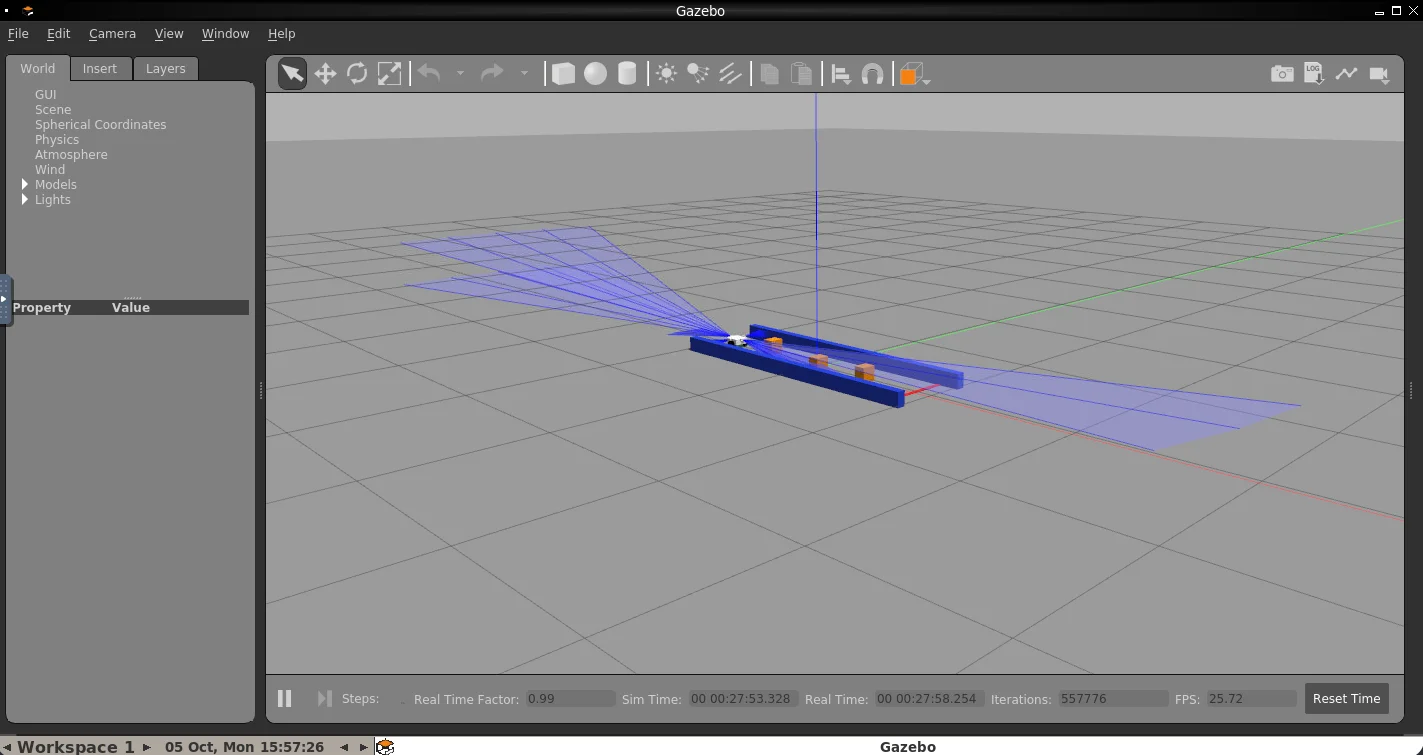

Puedes pausar o reanudar el tiempo simulado desde los controles de Gazebo.

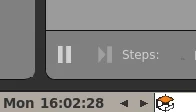

Cambia la posición y el ángulo del punto de vista haciendo clic y arrastrando el mouse. Puedes desplazar la vista con el botón izquierdo, rotarla con el botón central y usar la rueda para hacer zoom.

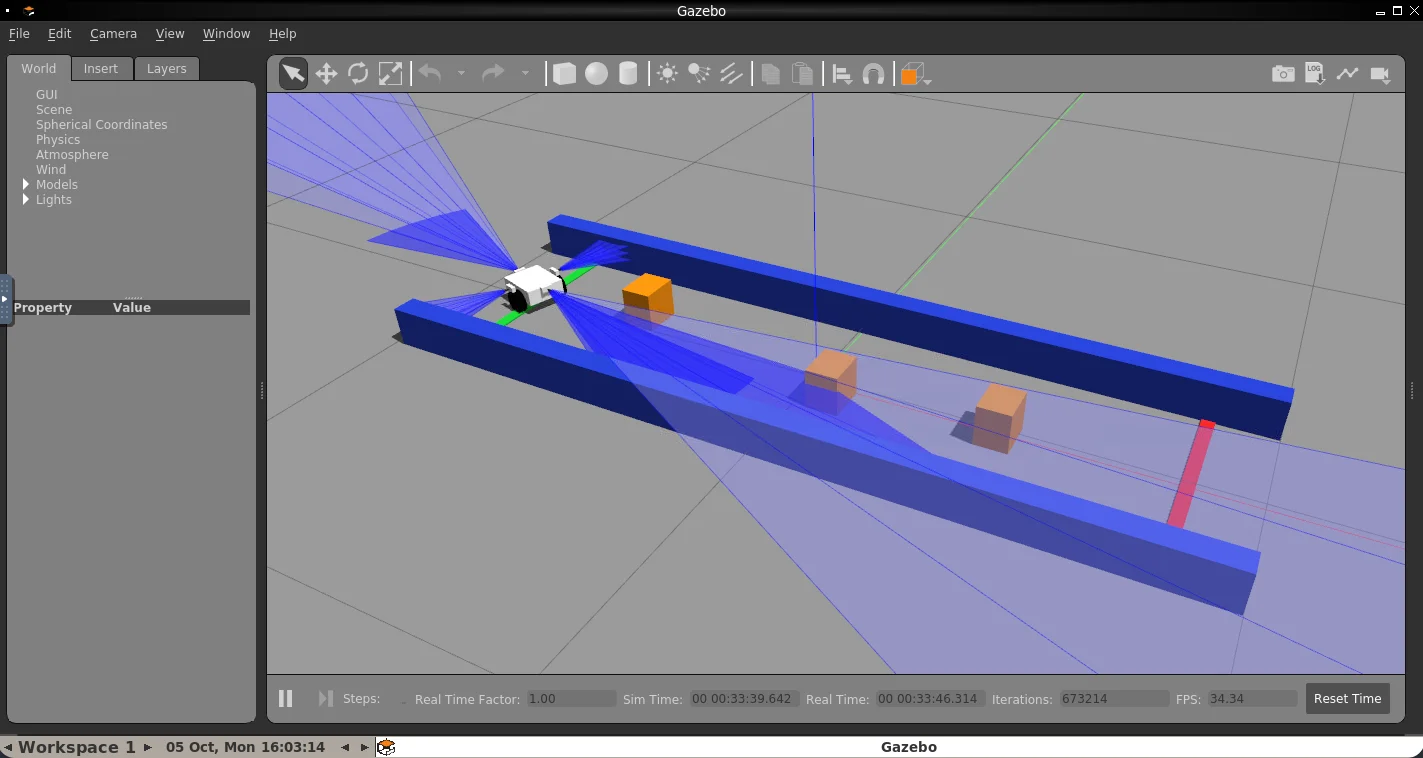

El tiempo transcurrido en el simulador es diferente al tiempo que transcurre realmente.

La etiqueta **Sim Time** en la parte inferior muestra el tiempo transcurrido en el simulador, y la etiqueta **Real Time** muestra el tiempo real transcurrido.

**Nota: la siguiente explicación está basada en el tiempo del simulador.**

# IDE para edición de código

El entorno incluye un IDE con VS Code para poder ver y editar el código fiuente en el directorio de trabajo o `workspace`. Además, desde VS Code podemos abrir la terminal para ejecutar programas de ROS para una mejor experiencia en la simulación.

1. Si no has iniciado el entorno, ejecuta `docker compose up --build`.
2. En el navegador abre http://localhost:3001/ para ver el IDE con VS Code.

## Compilar el código

Abre una terminal desde VS Code y ejecuta:

```sh
catkin_make
source devel/setup.bash
```

El comando `catkin_make` solo se ejecuta una vez, a menos que se modifique el código fuente. El comando `source` se debe ejecutar cada vez que se inician los contenedores con `docker compose` de lo contrario ros no podrá encontrar el código ejecutable.

## RViz
Rviz es una herramienta para visualizar el estado de los sensores del robot. Desde una terminal de VS Code ejecuta:

```sh
roslaunch karel_bringup karel_full.launch joystick:=false gui:=false
```

El joystick se desactiva para que no sobrescriba los comandos de velocidad enviados desde los notebooks. Detén el proceso con `Ctrl+C` cuando termines.

Verifica que Rviz haya iniciado en la pantalla del simulador. En Rviz, puedes visualizar información de los sensores que estan montados en el robot.

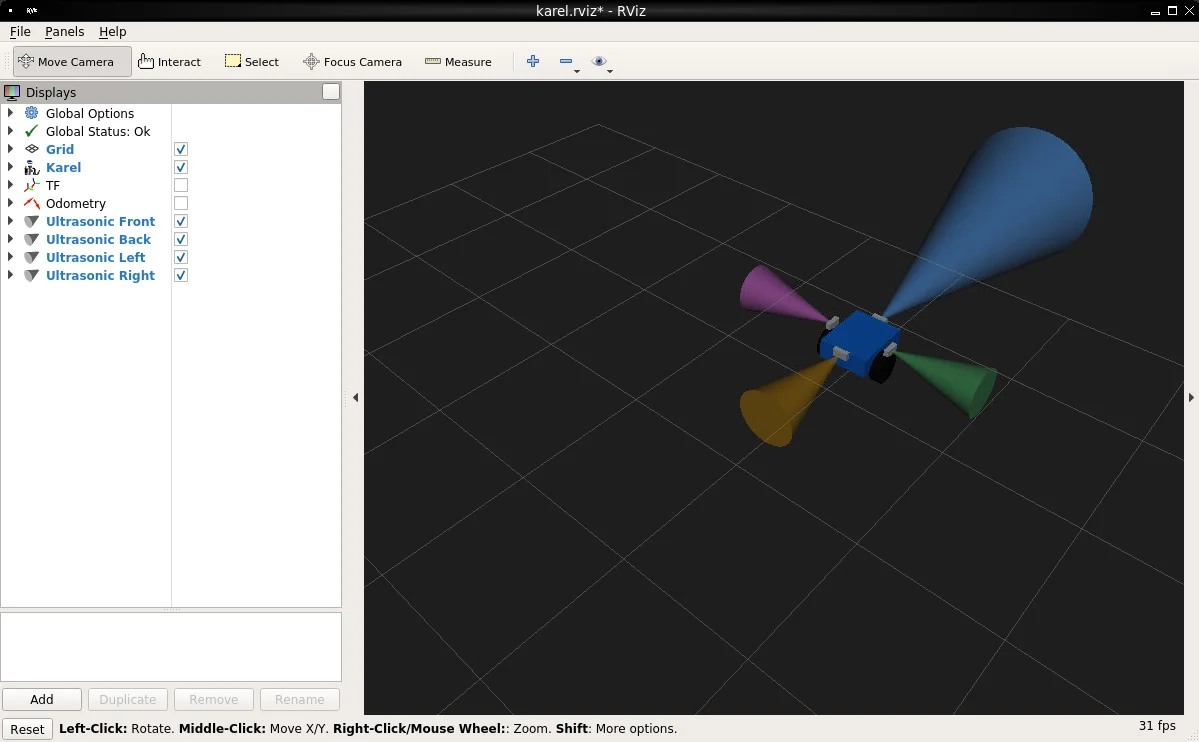

Para cambiar entre Gazebo y Rviz, da click en [Gazebo] o [RViz] en la parte inferior de la pantalla.

# Cómo usar screenshot y screencast

Primero, importa las bibliotecas requeridas:

In [ ]:
from utils import screen_shot, screen_cast


## Screenshot embedding

Puedes tomar e incorporar screenshots con el siguiente comando:

In [ ]:
screen_shot()

## Screencast embedding

También puedes incorporar un pequeño screencast como gif animado.

En el siguiente ejemplo, la pantalla se graba durante 10 segundos y el resultado se muestra en el cuaderno:


In [ ]:
screen_cast(10)

<div class="alert alert-block alert-info">
    <b>¿Qué sigue?</b>
    <p>En el siguiente notebook, vamos a capturar la información de los sensores montados en Karel, y mover la base hasta alcanzar la meta.</p>
</div>

# Información adicional

Creado por: Julio Cesar Cruz Estrada

Version: 1.0.0